# Ray Tune: median stopping, a stopper and the ResultGrid

Two grid trials under the median stopping rule and a MaximumIteration stopper; ResultGrid nodes pull a DataFrame of trial results and the error count.

**When to use it.** Inspecting a whole sweep after it ends: comparing trials in pandas and checking that none failed.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The builder lists a node in this graph in its *Experimental* section, so the node may change in later releases of the builder. The generated code ran on Ray 2.55.1.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

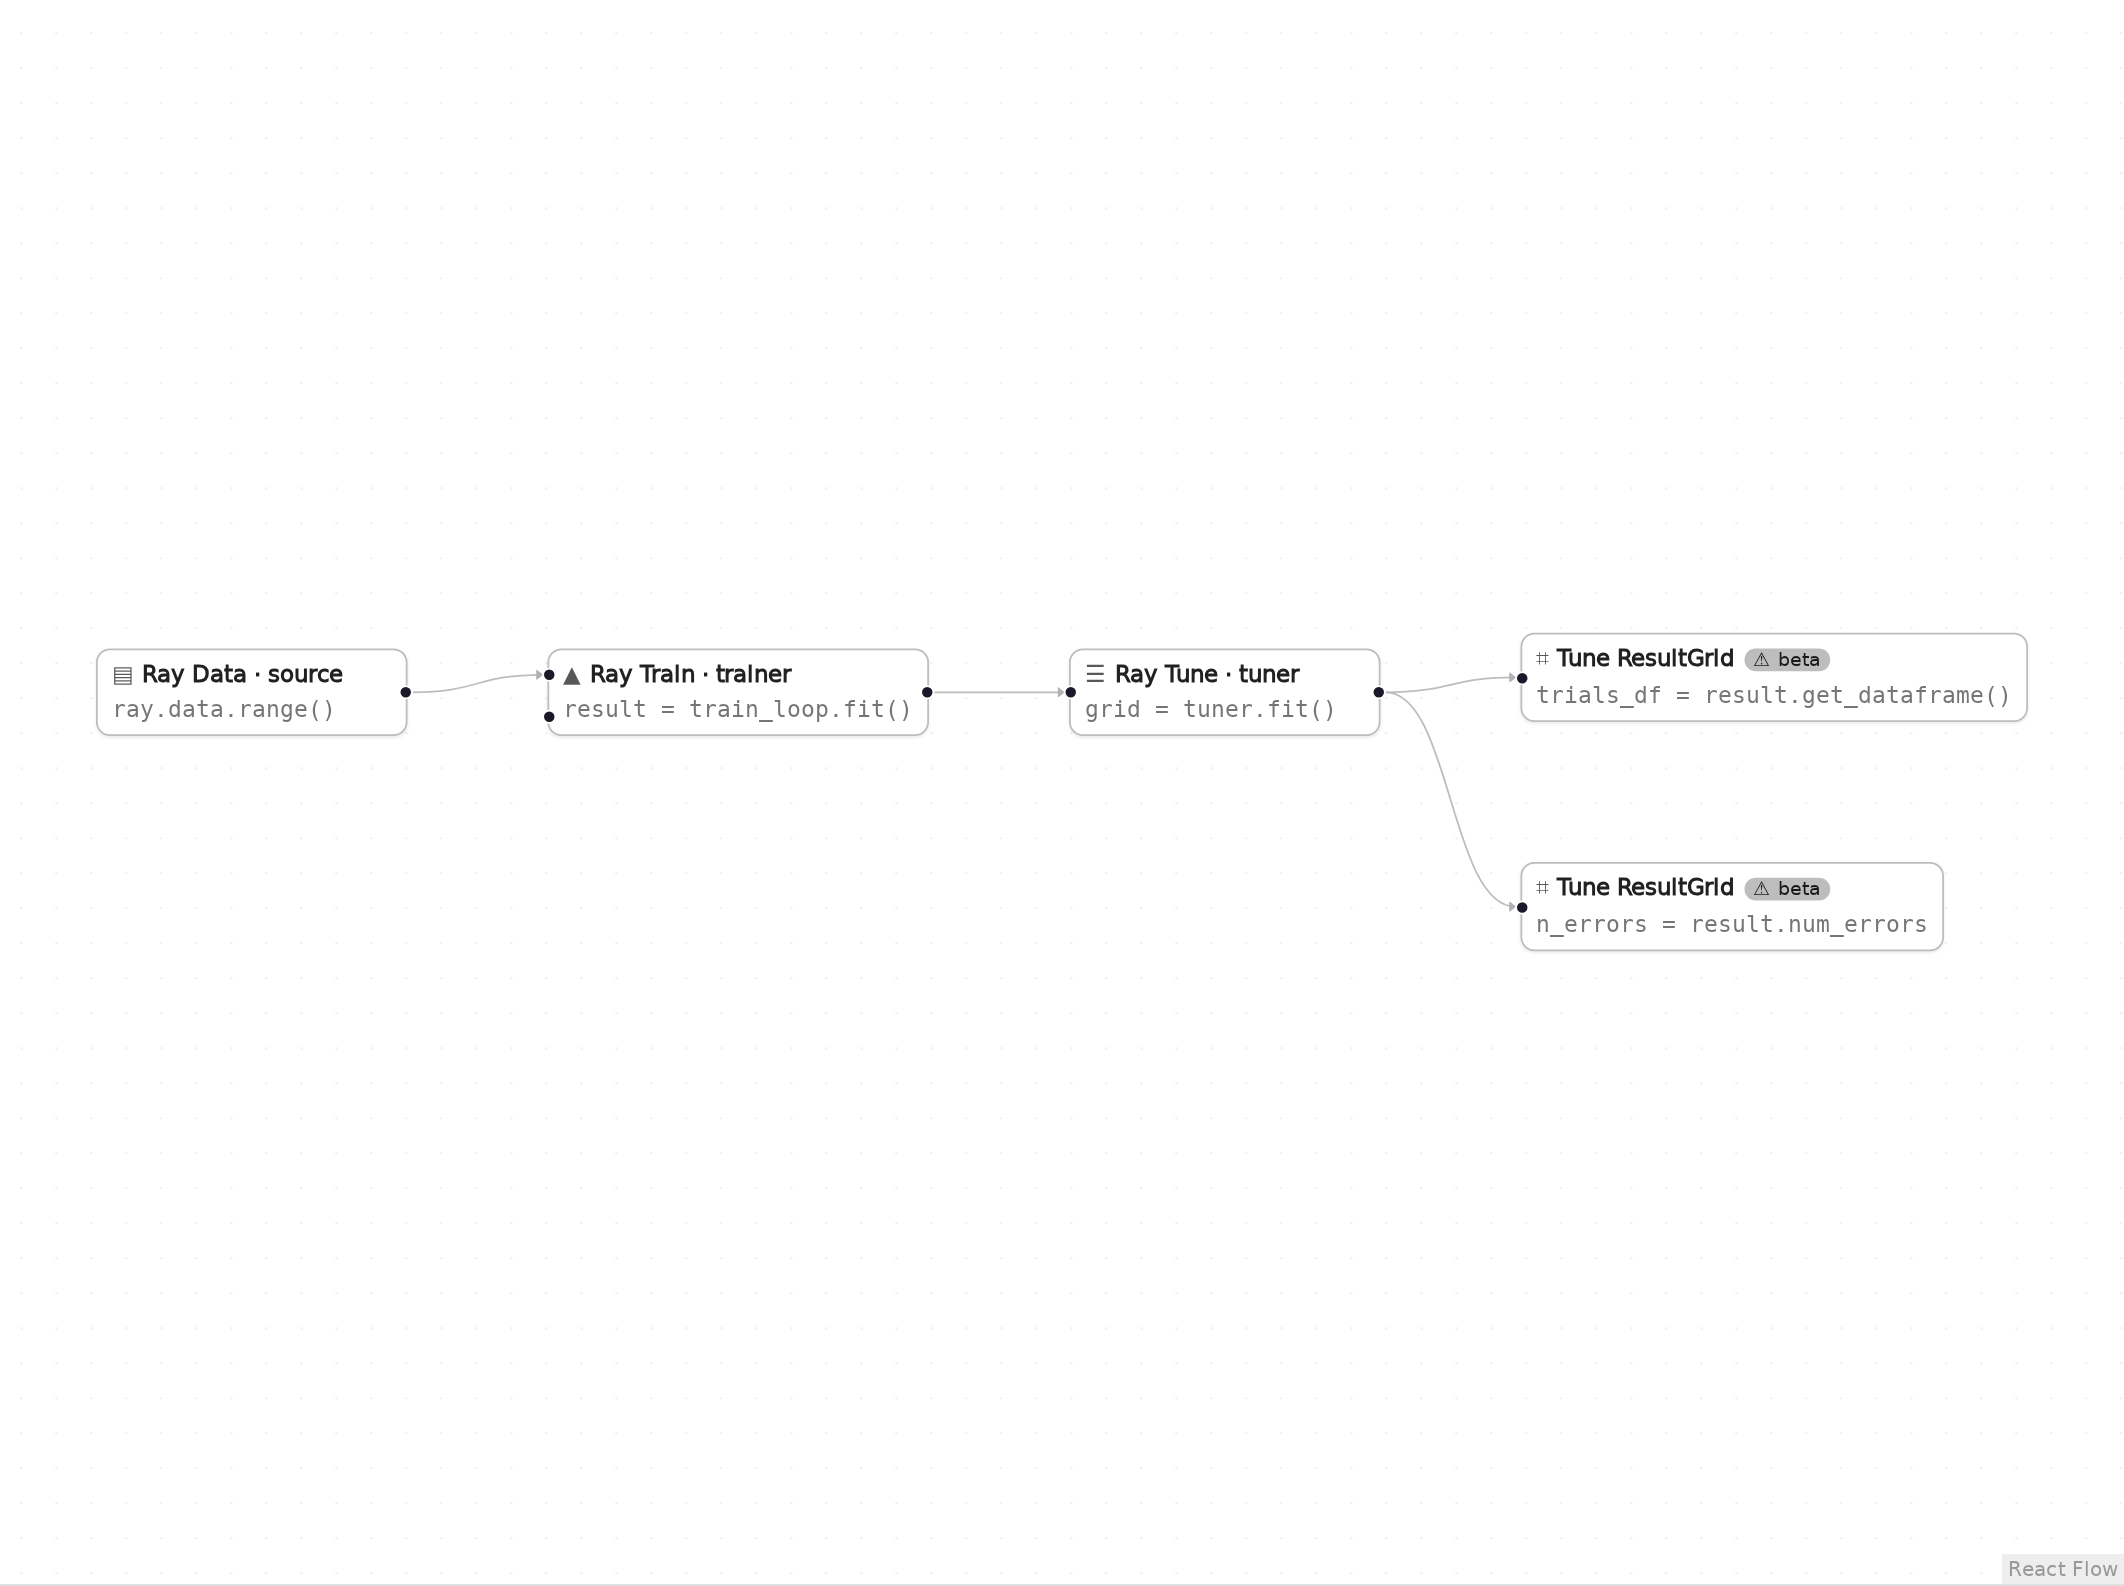

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import ray


def train_loop(config):
    lr = config["lr"]
    for _ in ray.train.get_dataset_shard("train").iter_batches(batch_size=4):
        pass
    for i in range(5):
        ray.train.report({"loss": float(lr) / (i + 1)})

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback
from ray.tune.schedulers import MedianStoppingRule
from ray.tune.stopper import MaximumIterationStopper

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(8)

def _tune_driver_n3(config):
    trainer = TorchTrainer(train_loop, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
    trainer.fit()

_tuner_n3 = Tuner(_tune_driver_n3, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1, scheduler=MedianStoppingRule(grace_period=1)), run_config=tune.RunConfig(stop=MaximumIterationStopper(max_iter=3)))
grid = _tuner_n3.fit()
best = grid.get_best_result()
trials_df = grid.get_dataframe()
n_errors = grid.num_errors

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert len(grid) == 2, len(grid)
assert n_errors == 0, n_errors
assert len(trials_df) == 2, trials_df
assert (trials_df["training_iteration"] == 3).all(), trials_df["training_iteration"]
print(trials_df[["loss", "training_iteration"]])
print("best lr =", best.config["train_loop_config"]["lr"])

       loss  training_iteration
0  0.003333                   3
1  0.033333                   3
best lr = 0.01


## How the graph maps to the code

Each step names a node in the picture by its label, the lines of the generated cell it produced, and what those lines do. Node ids such as `n1` are not drawn on the canvas. Where the builder names a variable after a node, the id is its suffix (for example `_tuner_n3`).

**Setup** (lines 1, 3–10 and 12–13)

```python
# Generated with Eugo's visual Ray builder
...
from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback
from ray.tune.schedulers import MedianStoppingRule
from ray.tune.stopper import MaximumIterationStopper
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 15)

```python
ds = ray.data.range(8)
```

The dataset every trial trains on.

**Tuner** (node `n3`, lines 17, 19 and 21–23)

```python
def _tune_driver_n3(config):
...
    trainer.fit()
...
_tuner_n3 = Tuner(_tune_driver_n3, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1, scheduler=MedianStoppingRule(grace_period=1)), run_config=tune.RunConfig(stop=MaximumIterationStopper(max_iter=3)))
grid = _tuner_n3.fit()
best = grid.get_best_result()
```

MedianStoppingRule stops a trial whose best result so far is worse than the median of the other trials' running averages at the same point, once the grace period has passed and enough other trials have reported; MaximumIterationStopper(max_iter=3) ends every trial after three reports; max_concurrent_trials=1 runs one trial at a time so the sweep fits on a small machine.

**Trainer** (node `n2`, line 18)

```python
    trainer = TorchTrainer(train_loop, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
```

The trainer each trial runs.

**Tune ResultGrid** (node `x1`, line 24)

```python
trials_df = grid.get_dataframe()
```

ResultGrid.get_dataframe(): one row per trial with its last reported metrics.

**Tune ResultGrid** (node `x2`, line 25)

```python
n_errors = grid.num_errors
```

ResultGrid.num_errors: how many trials failed.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()